# КП — Методи обчислювального інтелекту

Не для кожної задачі є точна формула чи алгоритм. Тоді рішення будують із нечітких правил, налаштовують за даними або шукають еволюційно. Кожна частина практикуму показує один такий метод на задачі управління водосховищем і прогнозування повені.


| Частина | Задача | Коли беруть такий метод | Кроки |
|---|---|---|---|
| 1. Нечітка система | оцінка рівня повені за словесними правилами | є знання експерта словами, а даних мало | 1–4 |
| 2. Нейро-нечітка модель | прогноз in6 за входами in2–in5 | є дані, потрібна модель із зрозумілими правилами | 5–8 |
| 3. Генетичний алгоритм | розподіл об'єктів між бригадами | треба знайти найкращий варіант серед мільйонів комбінацій | 9–11 |

---

Барабаш Катерина · ТВ-61мп · Варіант 2 · `Data_2.dat`, рядки 1–60, входи in2–in5, вихід in6

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad
import warnings
warnings.filterwarnings('ignore')

## Частина 1. Нечітка система

### 1. Підсистема

Лінгвістична змінна — величина, значення якої описують словами: «низький», «середній», «високий». `automf(3, names=TERMS)` ділить діапазон на три трикутні терми. Таблиця 3×3 — це дев'ять правил виду «ЯКЩО x=терм І y=терм ТО z=терм».

**Підсистеми (Варіант 2 — управління водосховищем):**
- 1.1: Рівень опадів × Середньодобова температура → Швидкість танення снігу
- 1.2: Максимальний рівень води × Площа басейну → Обсяг спуску води
- 1.3: Швидкість танення × Обсяг спуску → Очікуваний рівень повені

In [2]:
TERMS = ["низький", "середній", "високий"]

# Межі змінних: (min, max) для x, y, z
RANGES_11 = ((0, 60), (-10, 20), (0, 10))       # опади мм/д, температура °C, танення см/д
RANGES_12 = ((0, 12), (0, 500), (0, 100))        # рівень м, площа км², спуск млн м³
RANGES_13 = ((0, 10), (0, 100), (0, 8))          # танення, спуск, рівень повені м

# Таблиці правил: table[i][j] = терм z для x=TERMS[i], y=TERMS[j]
TABLE_11 = [["низький",  "низький",  "середній"],
            ["низький",  "середній", "високий"],
            ["середній", "високий",  "високий"]]

TABLE_12 = [row[:] for row in TABLE_11]
TABLE_13 = [row[:] for row in TABLE_11]


def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)
    for var in (x, y, z):
        var.automf(3, names=TERMS)
    rules = [ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]])
             for i in range(3) for j in range(3)]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))


def infer(ranges, table, method, x_value, y_value):
    sim = fuzzy_system(*ranges, table, method)
    sim.input["x"] = x_value
    sim.input["y"] = y_value
    sim.compute()
    return sim.output["z"]


print("Три нечіткі підсистеми побудовано:")
print("  1.1  опади × температура  →  швидкість танення снігу")
print("  1.2  рівень води × площа басейну  →  обсяг спуску води")
print("  1.3  швидкість танення × обсяг спуску  →  рівень повені")
print()
print(f"Терми кожної змінної: {TERMS}  (3 трикутні ФП на рівномірній сітці).")
print("Механізм: числовий вхід → ступені приналежності → активація 9 правил → дефазифікація → числовий вихід.")


Три нечіткі підсистеми побудовано:
  1.1  опади × температура  →  швидкість танення снігу
  1.2  рівень води × площа басейну  →  обсяг спуску води
  1.3  швидкість танення × обсяг спуску  →  рівень повені

Терми кожної змінної: ['низький', 'середній', 'високий']  (3 трикутні ФП на рівномірній сітці).
Механізм: числовий вхід → ступені приналежності → активація 9 правил → дефазифікація → числовий вихід.



1.1  опади × температура → танення  →  танення, см/добу
температура, °C   низький  середній   високий
опади, мм/добу                               
низький           низький   низький  середній
середній          низький  середній   високий
високий          середній   високий   високий

1.2  рівень × площа → спуск  →  спуск, млн м³
площа, км²   низький  середній   високий
рівень, м                               
низький      низький   низький  середній
середній     низький  середній   високий
високий     середній   високий   високий

1.3  танення × спуск → рівень повені  →  рівень повені, м
спуск, млн м³      низький  середній   високий
танення, см/добу                              
низький            низький   низький  середній
середній           низький  середній   високий
високий           середній   високий   високий


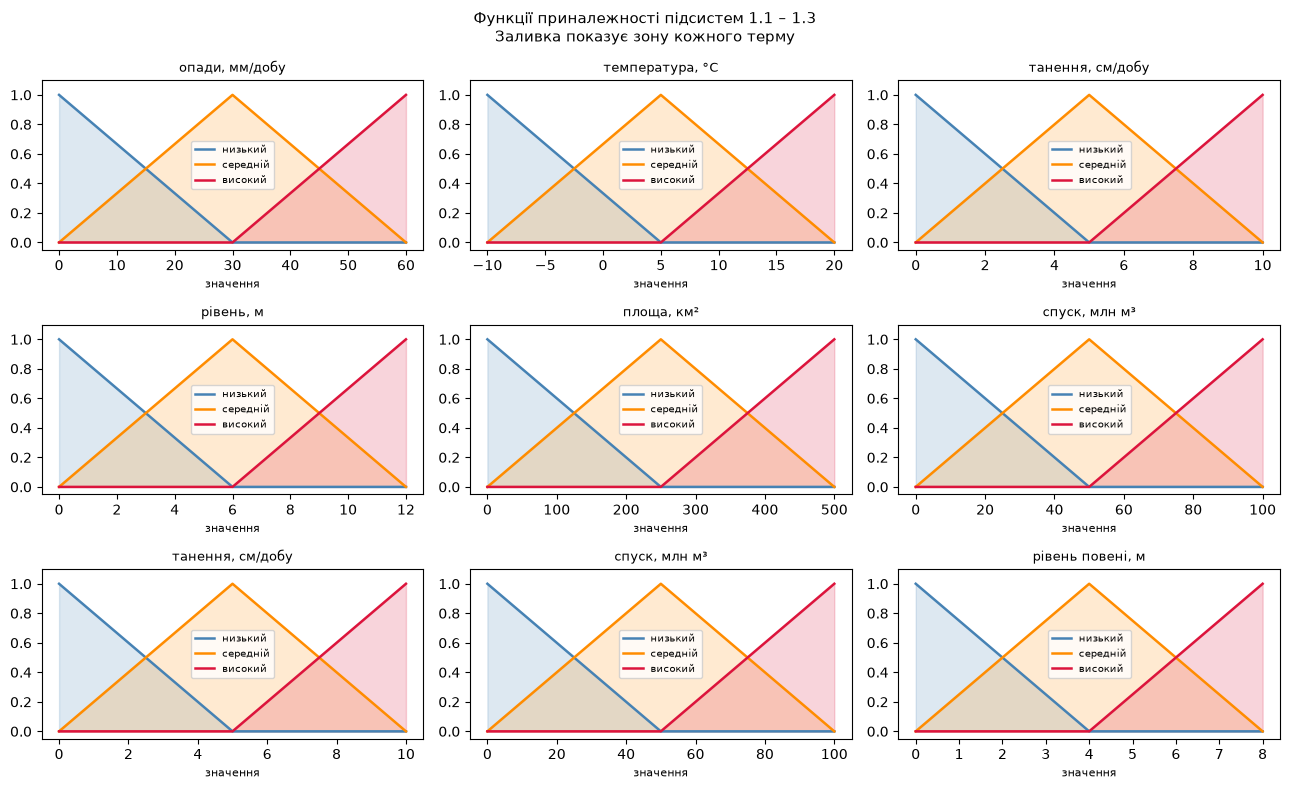

In [3]:
# Таблиці правил
subsystems = [
    ("1.1  опади × температура → танення",  TABLE_11,
     ("опади, мм/добу", "температура, °C", "танення, см/добу")),
    ("1.2  рівень × площа → спуск",         TABLE_12,
     ("рівень, м", "площа, км²", "спуск, млн м³")),
    ("1.3  танення × спуск → рівень повені", TABLE_13,
     ("танення, см/добу", "спуск, млн м³", "рівень повені, м")),
]
for name, table, (xl, yl, zl) in subsystems:
    df = pd.DataFrame(table, index=pd.Index(TERMS, name=xl),
                      columns=pd.Index(TERMS, name=yl))
    print(f"\n{name}  →  {zl}")
    print(df.to_string())

# Графіки функцій приналежності із заливкою зон
term_colors = {"низький": "steelblue", "середній": "darkorange", "високий": "crimson"}

fig, axes = plt.subplots(3, 3, figsize=(13, 8))
ranges_all = [RANGES_11, RANGES_12, RANGES_13]
for row, (name, table, labels) in enumerate(subsystems):
    for col, (lo, hi), lbl in zip(range(3), ranges_all[row], labels):
        ax = axes[row, col]
        u = np.linspace(lo, hi, 201)
        mid = (lo + hi) / 2
        abcs = {"низький": [lo, lo, mid], "середній": [lo, mid, hi], "високий": [mid, hi, hi]}
        for term, abc in abcs.items():
            mf = fuzz.trimf(u, abc)
            col_ = term_colors[term]
            ax.plot(u, mf, color=col_, lw=1.8, label=term)
            ax.fill_between(u, 0, mf, color=col_, alpha=0.18)
        ax.set_title(lbl, fontsize=9)
        ax.set_ylim(-0.05, 1.1)
        ax.set_xlabel("значення", fontsize=8)
        ax.legend(fontsize=7)

fig.suptitle("Функції приналежності підсистем 1.1 – 1.3\n"
             "Заливка показує зону кожного терму", fontsize=11)
fig.tight_layout()
plt.show()


### 2. Виведення за Мамдані

Значення 1.1 і 1.2 обчислюються нечітким виведенням із тестової точки варіанту 2 і потім подаються як входи до підсистеми 1.3.

**Два методи дефазифікації для підсистеми 1.3:**
- **Центроїд** — абсциса центру ваги агрегованої фігури (враховує всю площу під кривою виходу).
- **Середнє максимумів (MOM)** — середина ділянки з максимальним ступенем приналежності (орієнтується лише на пік, ігнорує форму решти фігури).

In [4]:
# Тестова точка варіанту 2
X_TEST_11 = (35, 12)    # опади 35 мм/д, температура 12°C
X_TEST_12 = (8.5, 320)  # рівень води 8.5 м, площа басейну 320 км²

print("Тестова точка (Варіант 2):")
print(f"  1.1  вхід: опади = {X_TEST_11[0]} мм/добу,  температура = {X_TEST_11[1]}°C")
print(f"  1.2  вхід: рівень води = {X_TEST_12[0]} м,  площа басейну = {X_TEST_12[1]} км²")
print()

out_11 = infer(RANGES_11, TABLE_11, "centroid", *X_TEST_11)
out_12 = infer(RANGES_12, TABLE_12, "centroid", *X_TEST_12)
out_13_centroid = infer(RANGES_13, TABLE_13, "centroid", out_11, out_12)
out_13_mom      = infer(RANGES_13, TABLE_13, "mom",      out_11, out_12)

print(f"1.1  ({X_TEST_11[0]} мм/д, {X_TEST_11[1]}°C)  →  швидкість танення снігу: {out_11:.3f} см/добу")
print(f"1.2  ({X_TEST_12[0]} м, {X_TEST_12[1]} км²)      →  обсяг спуску води: {out_12:.3f} млн м³")
print(f"\n1.3  вхід: танення = {out_11:.3f} см/д,  спуск = {out_12:.3f} млн м³")
print("     (значення з кроків 1.1 і 1.2 передаються як входи до підсистеми 1.3)\n")
print("Результати підсистеми 1.3 двома методами:")

results_13 = pd.DataFrame([
    {"Метод дефазифікації": "Центроїд",
     "Принцип": "центр ваги агрегованої фігури",
     "Рівень повені, м": round(out_13_centroid, 3)},
    {"Метод дефазифікації": "Середнє максимумів (MOM)",
     "Принцип": "середина ділянки максимального виходу",
     "Рівень повені, м": round(out_13_mom, 3)},
])
display(results_13)


Тестова точка (Варіант 2):
  1.1  вхід: опади = 35 мм/добу,  температура = 12°C
  1.2  вхід: рівень води = 8.5 м,  площа басейну = 320 км²

1.1  (35 мм/д, 12°C)  →  швидкість танення снігу: 5.516 см/добу
1.2  (8.5 м, 320 км²)      →  обсяг спуску води: 54.093 млн м³

1.3  вхід: танення = 5.516 см/д,  спуск = 54.093 млн м³
     (значення з кроків 1.1 і 1.2 передаються як входи до підсистеми 1.3)

Результати підсистеми 1.3 двома методами:


,Метод дефазифікації,Принцип,"Рівень повені, м"
0,Центроїд,центр ваги агрегованої фігури,4.021
1,Середнє максимумів (MOM),середина ділянки максимального виходу,4.000


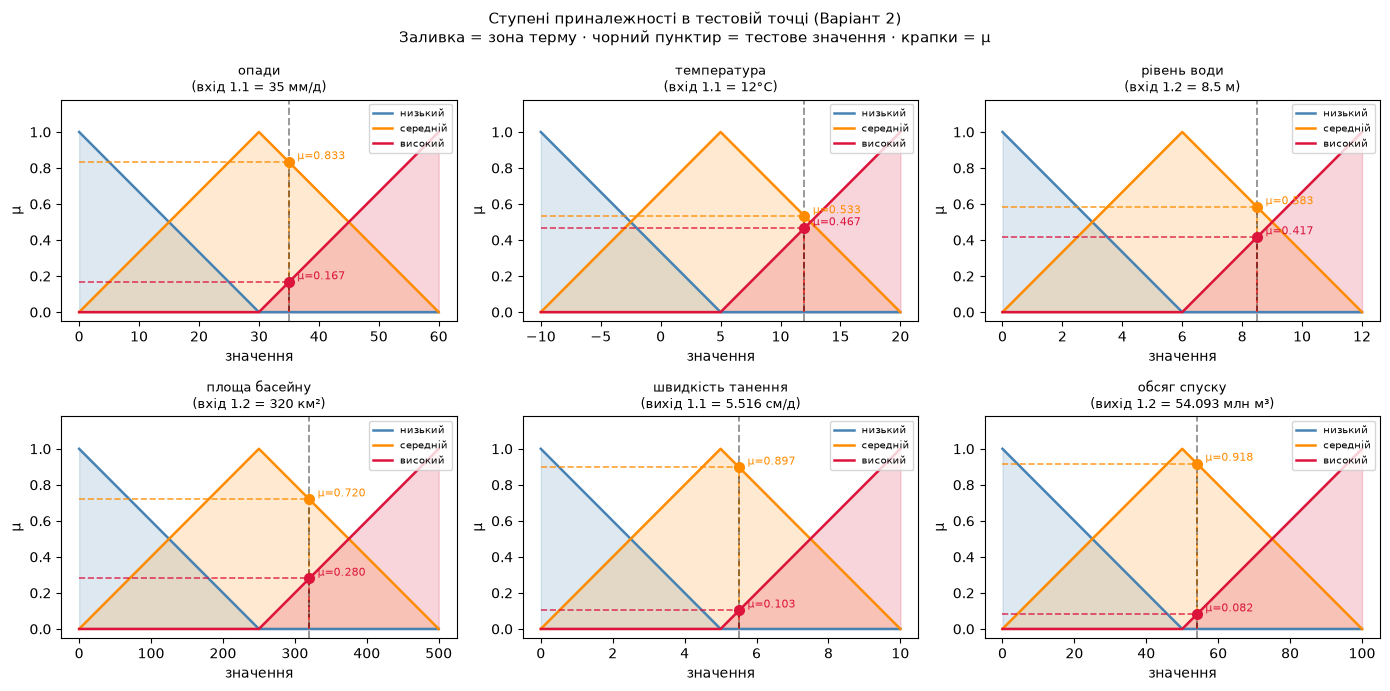

In [5]:
# Де тестова точка потрапляє на ФП кожної змінної?
# Вертикальна лінія — значення тесту.
# Крапка + пунктир — ступінь приналежності μ до кожного активного терму.
# Заливка — зона відповідного терму.

test_vars = [
    (RANGES_11[0], X_TEST_11[0], f"опади\n(вхід 1.1 = {X_TEST_11[0]} мм/д)"),
    (RANGES_11[1], X_TEST_11[1], f"температура\n(вхід 1.1 = {X_TEST_11[1]}°C)"),
    (RANGES_12[0], X_TEST_12[0], f"рівень води\n(вхід 1.2 = {X_TEST_12[0]} м)"),
    (RANGES_12[1], X_TEST_12[1], f"площа басейну\n(вхід 1.2 = {X_TEST_12[1]} км²)"),
    (RANGES_13[0], out_11,       f"швидкість танення\n(вихід 1.1 = {out_11:.3f} см/д)"),
    (RANGES_13[1], out_12,       f"обсяг спуску\n(вихід 1.2 = {out_12:.3f} млн м³)"),
]

term_colors = {"низький": "steelblue", "середній": "darkorange", "високий": "crimson"}

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (rng, val, title) in zip(axes.flat, test_vars):
    lo, hi = rng
    u = np.linspace(lo, hi, 201)
    mid = (lo + hi) / 2
    abcs = {"низький": [lo, lo, mid], "середній": [lo, mid, hi], "високий": [mid, hi, hi]}
    for term, abc in abcs.items():
        mf = fuzz.trimf(u, abc)
        mu = float(fuzz.interp_membership(u, mf, val))
        col = term_colors[term]
        ax.plot(u, mf, color=col, lw=1.8, label=term)
        ax.fill_between(u, 0, mf, color=col, alpha=0.18)
        if mu > 1e-9:
            ax.vlines(val, 0, mu, colors=col, linestyles="dashed", lw=1.2, alpha=0.8)
            ax.hlines(mu, lo, val, colors=col, linestyles="dashed", lw=1.2, alpha=0.8)
            ax.plot(val, mu, "o", color=col, markersize=7, zorder=5)
            ax.annotate(f"μ={mu:.3f}", xy=(val, mu),
                        xytext=(6, 2), textcoords="offset points",
                        fontsize=8, color=col)
    ax.axvline(val, color="black", lw=1.4, linestyle="--", alpha=0.4)
    ax.set_title(title, fontsize=9)
    ax.set_ylim(-0.05, 1.18)
    ax.set_xlabel("значення")
    ax.set_ylabel("μ")
    ax.legend(fontsize=7, loc="upper right")

fig.suptitle("Ступені приналежності в тестовій точці (Варіант 2)\n"
             "Заливка = зона терму · чорний пунктир = тестове значення · крапки = μ",
             fontsize=11)
fig.tight_layout()
plt.show()


Щоб побачити, чому два методи дали різні числа (центроїд → 4.021 м, середнє максимумів → 4.000 м), виведемо силу кожного з дев'яти правил підсистеми 1.3.

In [6]:
def memberships(value, value_range):
    low, high = value_range
    universe = np.linspace(low, high, 201)
    middle = (low + high) / 2
    shapes = {
        "низький":  [low, low, middle],
        "середній": [low, middle, high],
        "високий":  [middle, high, high],
    }
    return {term: float(fuzz.interp_membership(universe, fuzz.trimf(universe, abc), value))
            for term, abc in shapes.items()}


mu_x = memberships(out_11, RANGES_13[0])
mu_y = memberships(out_12, RANGES_13[1])

print("Ступені приналежності вхідних значень підсистеми 1.3:")
print(f"  x = танення = {out_11:.3f} см/д  →  "
      + ",  ".join(f"{t}: μ={v:.6f}" for t, v in mu_x.items()))
print(f"  y = спуск   = {out_12:.3f} млн м³  →  "
      + ",  ".join(f"{t}: μ={v:.6f}" for t, v in mu_y.items()))
print()
print("Сила правила з термом 'низький' завжди 0: цей терм неактивний у тестовій точці.")
print()

strengths = pd.DataFrame([
    {"x (танення)": tx, "y (спуск)": ty, "z (повінь)": TABLE_13[i][j],
     "сила": min(mu_x[tx], mu_y[ty])}
    for i, tx in enumerate(TERMS) for j, ty in enumerate(TERMS)
])
display(
    strengths.sort_values("сила", ascending=False)
             .reset_index(drop=True)
             .style.format({"сила": "{:.10f}"})
)


Ступені приналежності вхідних значень підсистеми 1.3:
  x = танення = 5.516 см/д  →  низький: μ=0.000000,  середній: μ=0.896808,  високий: μ=0.103192
  y = спуск   = 54.093 млн м³  →  низький: μ=0.000000,  середній: μ=0.918139,  високий: μ=0.081861

Сила правила з термом 'низький' завжди 0: цей терм неактивний у тестовій точці.



,x (танення),y (спуск),z (повінь),сила
0,середній,середній,середній,0.8968081445
1,високий,середній,високий,0.1031918555
2,середній,високий,високий,0.0818607834
3,високий,високий,високий,0.0818607834
4,низький,низький,низький,0.0000000000
5,низький,середній,низький,0.0000000000
6,низький,високий,середній,0.0000000000
7,середній,низький,низький,0.0000000000
8,високий,низький,середній,0.0000000000


### 3. Поверхня реакції

Поверхня реакції — це повна картина роботи системи: для **кожної** пари значень (танення, спуск) вона показує, який рівень повені дасть система. Горизонтальні осі — два входи, вертикальна / колір — вихід.

На відміну від тестової точки, де ми отримали одне число, поверхня відповідає на питання: *«А що буде, якщо входи будуть іншими?»* — і показує це одразу для всього діапазону.

- **3D-вигляд** (ліворуч) — інтуїтивно показує, де система дає низький, середній або високий рівень повені.
- **Вид зверху з ізолініями** (праворуч) — зручний для читання точних значень. Колір = той самий вихід, лінії з'єднують точки з однаковим рівнем повені.
- **Чорна точка** — тестова точка варіанту 2.

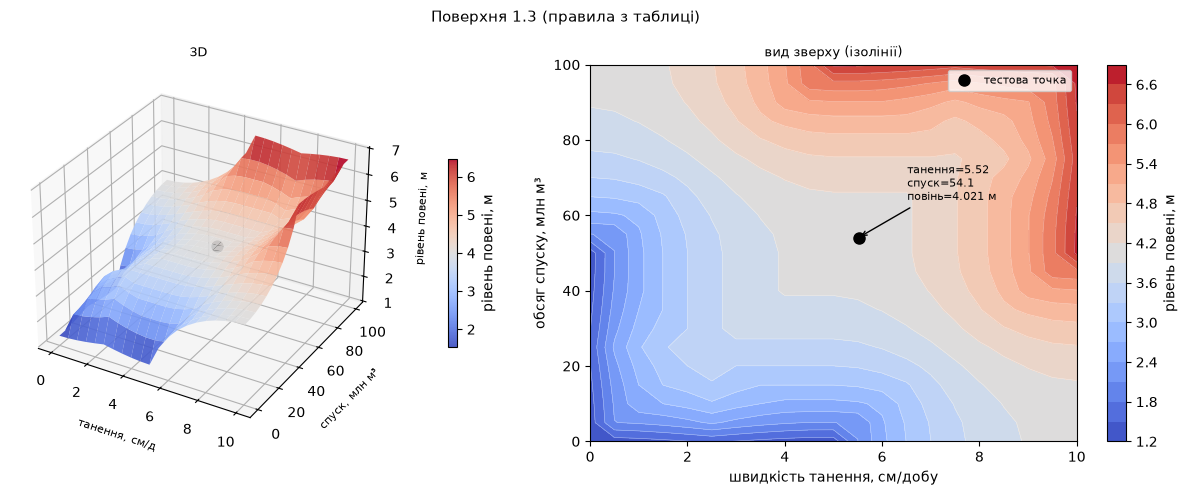

In [7]:
from mpl_toolkits.mplot3d import Axes3D

def surface(table):
    xs = np.linspace(*RANGES_13[0], 21)
    ys = np.linspace(*RANGES_13[1], 21)
    sim = fuzzy_system(*RANGES_13, table, "centroid")
    Z = np.zeros((len(ys), len(xs)))
    for i, y_val in enumerate(ys):
        for j, x_val in enumerate(xs):
            sim.input["x"] = x_val
            sim.input["y"] = y_val
            sim.compute()
            Z[i, j] = sim.output["z"]
    return xs, ys, Z


def plot_surface(xs, ys, Z, title, label="рівень повені, м", test_pt=None):
    X_mesh, Y_mesh = np.meshgrid(xs, ys)
    fig = plt.figure(figsize=(13, 5))

    # --- 3D поверхня ---
    ax3 = fig.add_subplot(121, projection="3d")
    surf = ax3.plot_surface(X_mesh, Y_mesh, Z, cmap="coolwarm", alpha=0.9, linewidth=0)
    fig.colorbar(surf, ax=ax3, label=label, shrink=0.5, pad=0.1)
    if test_pt is not None:
        ax3.scatter([test_pt[0]], [test_pt[1]], [test_pt[2]],
                    color="black", s=60, zorder=5)
    ax3.set_xlabel("танення, см/д", fontsize=8, labelpad=6)
    ax3.set_ylabel("спуск, млн м³", fontsize=8, labelpad=6)
    ax3.set_zlabel(label, fontsize=8)
    ax3.set_title("3D", fontsize=9)

    # --- 2D контур (вид зверху) ---
    ax2 = fig.add_subplot(122)
    cf = ax2.contourf(xs, ys, Z, levels=20, cmap="coolwarm")
    ax2.contour(xs, ys, Z, levels=20, colors="white", linewidths=0.4, alpha=0.5)
    fig.colorbar(cf, ax=ax2, label=label)
    if test_pt is not None:
        ax2.plot(test_pt[0], test_pt[1], "ko", markersize=8, label="тестова точка")
        ax2.annotate(
            f"танення={test_pt[0]:.2f}\nспуск={test_pt[1]:.1f}\nповінь={test_pt[2]:.3f} м",
            xy=(test_pt[0], test_pt[1]),
            xytext=(test_pt[0] + 1.0, test_pt[1] + 10),
            fontsize=8,
            arrowprops=dict(arrowstyle="->", color="black"),
        )
        ax2.legend(fontsize=8)
    ax2.set_xlabel("швидкість танення, см/добу")
    ax2.set_ylabel("обсяг спуску, млн м³")
    ax2.set_title("вид зверху (ізолінії)", fontsize=9)

    fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()


xs, ys, Z_old = surface(TABLE_13)
plot_surface(xs, ys, Z_old, "Поверхня 1.3 (правила з таблиці)",
             test_pt=(out_11, out_12, out_13_centroid))


### 4. Одне правило

Змінимо правило «танення середнє І спуск середній → повінь середня» на «→ повінь висока» і подивимося, як поверхня змінилася саме там, де це правило спрацьовує.

центроїд:         було 4.021 м, стало 6.654 м
середнє максимумів: було 4.000 м, стало 7.782 м


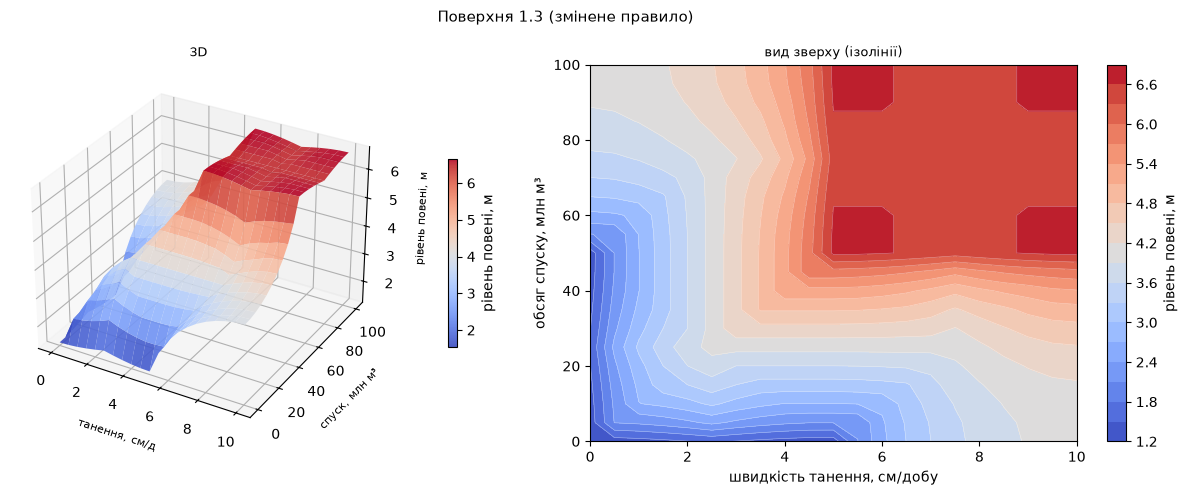

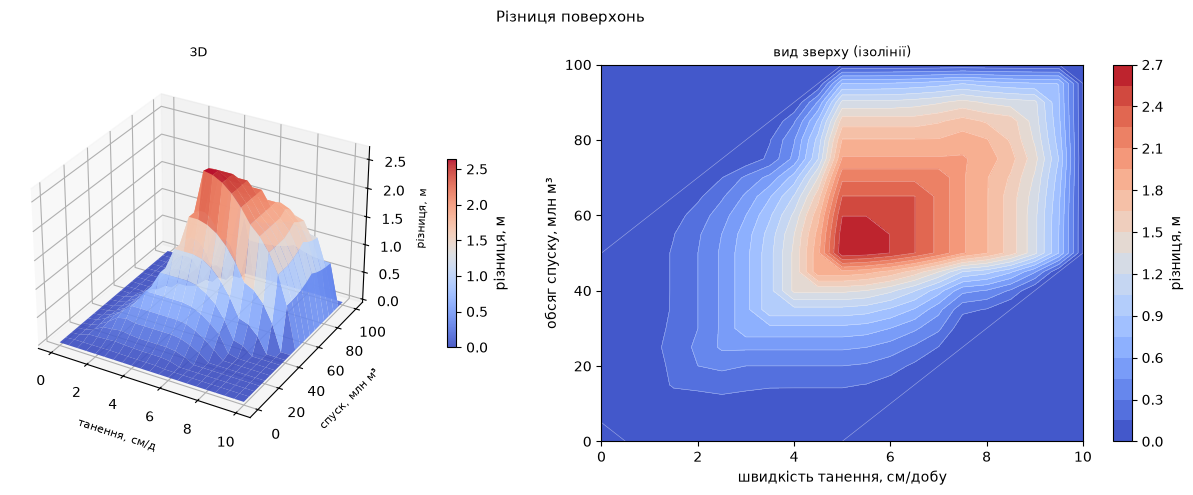

In [8]:
TABLE_13_NEW = [row[:] for row in TABLE_13]
TABLE_13_NEW[1][1] = "високий"   # рядок «середній», стовпець «середній»

new_centroid = infer(RANGES_13, TABLE_13_NEW, "centroid", out_11, out_12)
new_mom      = infer(RANGES_13, TABLE_13_NEW, "mom",      out_11, out_12)

print(f"центроїд:         було {out_13_centroid:.3f} м, стало {new_centroid:.3f} м")
print(f"середнє максимумів: було {out_13_mom:.3f} м, стало {new_mom:.3f} м")

_, _, Z_new = surface(TABLE_13_NEW)
plot_surface(xs, ys, Z_new, "Поверхня 1.3 (змінене правило)")
plot_surface(xs, ys, Z_new - Z_old, "Різниця поверхонь", label="різниця, м")

---

## Частина 2. Нейро-нечітка модель

### 5. Дані

Модель Сугено нульового порядку: «ЯКЩО входи близькі до центру правила ТО y = число». Вихід — середнє висновків правил, зважене ступенями активації. Похибка — **RMSE** (корінь із середньоквадратичної похибки): менше = точніше.

**Варіант 2:** рядки 1–60, входи in2–in5, вихід in6.

---

**Навчальна і тестова вибірки**

З 60 рядків 75% (45 точок) відкладено для **навчання** — модель підбирає свої параметри саме на них.  
Решта 25% (15 точок) утворюють **тестову** вибірку — модель їх під час навчання не бачила.

| | Навчальна RMSE | Тестова RMSE |
|---|---|---|
| **Що вимірює** | наскільки модель підійшла до даних, на яких вчилась | наскільки добре вона працює на нових, невідомих даних |
| **Мала** | модель добре описує навчальні дані | модель справді узагальнює — це хороший знак |
| **Велика** | модель не навчилась навіть на своїх даних | тестова >> навчальна → перенавчання: запам'ятала, але не узагальнила |

**Базова лінія — прогноз середнім:** «модель», що завжди повертає середнє значення навчальної вибірки, ігноруючи входи. Будь-яка нечітка модель повинна давати RMSE нижчу за цей рівень.

In [9]:
raw = pd.read_csv("Data_2.dat", sep=r"\s+", header=None,
                  names=["in1","in2","in3","in4","in5","in6"])

sample = raw.iloc[0:60][["in2","in3","in4","in5","in6"]].reset_index(drop=True)
X = sample.iloc[:, :-1].to_numpy()
y = sample.iloc[:, -1].to_numpy()

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0)

x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
x_tr = (X_tr - x_min) / (x_max - x_min)
x_te = (X_te - x_min) / (x_max - x_min)

y_min  = y_tr.min()
y_span = y_tr.max() - y_tr.min()
t_tr = (y_tr - y_min) / y_span
t_te = (y_te - y_min) / y_span

rmse_mean_tr = float(np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2)))
rmse_mean_te = float(np.sqrt(np.mean((y_te - y_tr.mean()) ** 2)))

overview = pd.DataFrame([
    {"": "Кількість точок",
     "Навчальна вибірка\n(модель на ній вчиться)": f"{X_tr.shape[0]} спостережень × {X_tr.shape[1]} входи",
     "Тестова вибірка\n(модель їх не бачила)": f"{X_te.shape[0]} спостережень × {X_te.shape[1]} входи"},
    {"": "Базова лінія RMSE\n(прогноз середнім)",
     "Навчальна вибірка\n(модель на ній вчиться)": f"{rmse_mean_tr:.3f}",
     "Тестова вибірка\n(модель їх не бачила)": f"{rmse_mean_te:.3f}"},
]).set_index("")

display(overview)


,Навчальна вибірка\n(модель на ній вчиться),Тестова вибірка\n(модель їх не бачила)
,,
Кількість точок,45 спостережень × 4 входи,15 спостережень × 4 входи
Базова лінія RMSE\n(прогноз середнім),1.125,0.861


In [10]:
# --- Готове ядро моделі Сугено (незмінне) ---

def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2*k]).reshape(c, -1), theta[2*k:]

def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))

def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span

def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(
        w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta

def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

print("Ядро моделі готове.")


Ядро моделі готове.


### 6. Субтрактивна кластеризація

Субтрактивна кластеризація сама визначає кількість кластерів (правил). Малий радіус `ra` → багато дрібних кластерів, великий → кілька великих.

In [11]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra**2, 4 / (1.5 * ra)**2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(
            potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]


data_sc = np.column_stack([x_tr, t_tr])

sc_rows = []
for ra in (0.3, 0.5, 0.8):
    centers_all = subclust(data_sc, ra)
    c = len(centers_all)
    centers_in = centers_all[:, :x_tr.shape[1]]
    widths = np.full_like(centers_in, ra / 2)
    theta0 = pack(centers_in, np.clip(widths, 0.08, 0.8))
    theta_sc = tune(theta0, c)
    tr_err, te_err = errors(theta_sc, c)
    sc_rows.append({"ra (радіус)": ra,
                    "Правил": c,
                    "Навчальна RMSE\n(45 точок)": round(tr_err, 3),
                    "Тестова RMSE\n(15 нових точок)": round(te_err, 3)})

sc_table = pd.DataFrame(sc_rows)
best_sc = sc_table["Тестова RMSE\n(15 нових точок)"].idxmin()

def highlight_best(row):
    return ["background-color: #d4edda; font-weight: bold"
            if row.name == best_sc else "" for _ in row]

display(sc_table.style.apply(highlight_best, axis=1)
               .format({"Навчальна RMSE\n(45 точок)": "{:.3f}",
                        "Тестова RMSE\n(15 нових точок)": "{:.3f}"}))


,ra (радіус),Правил,Навчальна RMSE (45 точок),Тестова RMSE (15 нових точок)
0,0.300000,19,0.076,0.835
1,0.500000,8,0.287,1.068
2,0.800000,2,0.662,0.883


### 7. Правила з c-means і налаштування

In [12]:
def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(
        np.column_stack([x_tr, t_tr]).T, c=c, m=2.0,
        error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.array([
        np.sqrt((u[k]**2 @ (x_tr - centers[k])**2) / (u[k]**2).sum())
        for k in range(c)
    ])
    return pack(centers, np.clip(widths, 0.08, 0.8))


theta       = cmeans_rules(3)
theta_tuned = tune(theta, 3)

tr_before, te_before = errors(theta, 3)
tr_after,  te_after  = errors(theta_tuned, 3)

rows = [
    {"Модель": "Прогноз середнім (базова лінія)",
     "Навчальна RMSE\n(45 точок)": round(rmse_mean_tr, 3),
     "Тестова RMSE\n(15 нових точок)": round(rmse_mean_te, 3),
     "Висновок": "Завжди повертає середнє — не враховує входи. Це мінімальна планка, яку модель має перевищити."},
    {"Модель": "3 правила c-means, до налаштування",
     "Навчальна RMSE\n(45 точок)": round(tr_before, 3),
     "Тестова RMSE\n(15 нових точок)": round(te_before, 3),
     "Висновок": "Тестова RMSE нижча за базову — модель справді навчилась і добре узагальнює на нових даних."},
    {"Модель": "3 правила c-means, після налаштування",
     "Навчальна RMSE\n(45 точок)": round(tr_after, 3),
     "Тестова RMSE\n(15 нових точок)": round(te_after, 3),
     "Висновок": "Навчальна похибка зменшилась, але тестова зросла — ознака перенавчання на малій вибірці (45 точок)."},
]
df_cmp = pd.DataFrame(rows)

best_te_idx = df_cmp["Тестова RMSE\n(15 нових точок)"].idxmin()

def highlight_best(row):
    return ["background-color: #d4edda; font-weight: bold"
            if row.name == best_te_idx else "" for _ in row]

display(df_cmp.style.apply(highlight_best, axis=1)
              .format({"Навчальна RMSE\n(45 точок)": "{:.3f}",
                       "Тестова RMSE\n(15 нових точок)": "{:.3f}"}))


,Модель,Навчальна RMSE (45 точок),Тестова RMSE (15 нових точок),Висновок
0,Прогноз середнім (базова лінія),1.125,0.861,"Завжди повертає середнє — не враховує входи. Це мінімальна планка, яку модель має перевищити."
1,"3 правила c-means, до налаштування",1.056,0.638,Тестова RMSE нижча за базову — модель справді навчилась і добре узагальнює на нових даних.
2,"3 правила c-means, після налаштування",0.704,1.110,"Навчальна похибка зменшилась, але тестова зросла — ознака перенавчання на малій вибірці (45 точок)."


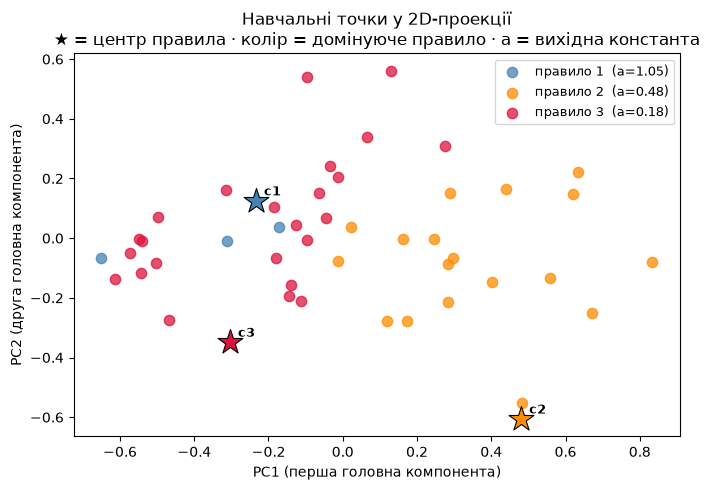

In [13]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=0)
X2d = pca.fit_transform(x_tr)
c3, _, a3 = unpack(theta_tuned, 3)
centers_2d = pca.transform(c3)

w_tr = activation(theta_tuned, x_tr, 3)
dominant = w_tr.argmax(axis=1)

rule_colors = ["steelblue", "darkorange", "crimson"]

fig, ax = plt.subplots(figsize=(7, 5))

for k in range(3):
    mask = dominant == k
    ax.scatter(X2d[mask, 0], X2d[mask, 1],
               color=rule_colors[k], alpha=0.75, s=55,
               label=f"правило {k+1}  (a={a3[k]:.2f})")
    ax.scatter(*centers_2d[k], marker="*", s=350,
               color=rule_colors[k], edgecolors="black", linewidth=0.8, zorder=5)
    ax.annotate(f"c{k+1}", xy=centers_2d[k],
                xytext=(6, 4), textcoords="offset points", fontsize=9, fontweight="bold")

ax.set_xlabel("PC1 (перша головна компонента)")
ax.set_ylabel("PC2 (друга головна компонента)")
ax.set_title("Навчальні точки у 2D-проекції\n"
             "★ = центр правила · колір = домінуюче правило · a = вихідна константа")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()


### 8. Кількість правил

,Правил,Навчальна RMSE (45 точок),Тестова RMSE (15 нових точок)
0,2,0.823,0.597
1,3,0.704,1.110
2,4,0.416,0.865
3,5,0.439,1.146
4,6,0.316,1.164


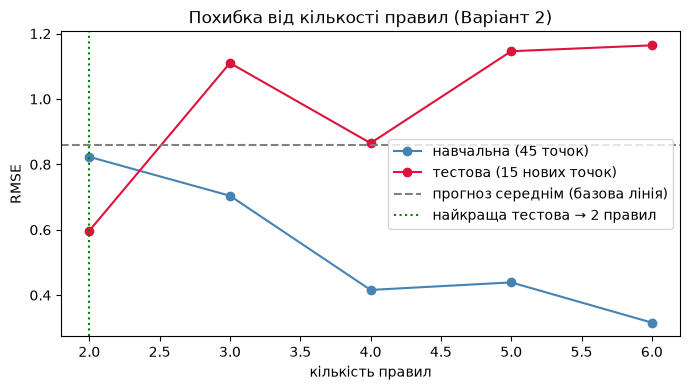

In [14]:
rule_rows = []
for c in range(2, 7):
    tr_err, te_err = errors(tune(cmeans_rules(c), c), c)
    rule_rows.append({"Правил": c,
                      "Навчальна RMSE\n(45 точок)": round(tr_err, 3),
                      "Тестова RMSE\n(15 нових точок)": round(te_err, 3)})

rules_table = pd.DataFrame(rule_rows)
best_idx = rules_table["Тестова RMSE\n(15 нових точок)"].idxmin()

def highlight_best(row):
    return ["background-color: #d4edda; font-weight: bold"
            if row.name == best_idx else "" for _ in row]

display(rules_table.style.apply(highlight_best, axis=1)
                   .format({"Навчальна RMSE\n(45 точок)": "{:.3f}",
                             "Тестова RMSE\n(15 нових точок)": "{:.3f}"}))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rules_table["Правил"], rules_table["Навчальна RMSE\n(45 точок)"],
        marker="o", color="steelblue", label="навчальна (45 точок)")
ax.plot(rules_table["Правил"], rules_table["Тестова RMSE\n(15 нових точок)"],
        marker="o", color="crimson", label="тестова (15 нових точок)")
ax.axhline(rmse_mean_te, color="gray", linestyle="--", label="прогноз середнім (базова лінія)")
best_c = int(rules_table.loc[best_idx, "Правил"])
ax.axvline(best_c, color="green", linestyle=":", linewidth=1.5,
           label=f"найкраща тестова → {best_c} правил")
ax.set_xlabel("кількість правил")
ax.set_ylabel("RMSE")
ax.set_title("Похибка від кількості правил (Варіант 2)")
ax.legend()
fig.tight_layout()
plt.show()


---

## Частина 3. Розподіл бригад

### 9. Задача й жадібний алгоритм

**Об'єкти** — 74 рядки з `Data_2.dat`. Кожен описується двома числами:
- **t** = 0.5 + in4 / 12 — час обслуговування одного об'єкта (год)
- **v** = in6 — цінність: прогнозовані втрати, яких уникнемо, якщо обслугуємо цей об'єкт

**Мета:** відібрати об'єкти та розподілити їх між трьома бригадами (фонд: 9 / 6 / 3 год) так, щоб **сума v** призначених об'єктів була максимальною, а жодна бригада не перевищила свій фонд. Оскільки сумарний час усіх 74 об'єктів набагато більший за 18 год, обслугувати всіх неможливо.

**Терміни результатів:**

| Термін | Що означає |
|---|---|
| **Сума цінності** | Σ v для всіх призначених об'єктів — чим більше, тим краще |
| **Завантаження [a / b / c]** | години, витрачені кожною бригадою: [бр.1, бр.2, бр.3] |
| **Перевищення** | сума годин понад фонд по всіх бригадах; 0 = план допустимий |

**Жадібний алгоритм** сортує об'єкти за спаданням v/t (цінність за годину) і кладе кожен у першу бригаду, де він ще вміщується за фондом. Не перебирає комбінації — швидкий, але може пропустити кращий розподіл.


In [15]:
FUND     = (9, 6, 3)   # фонд часу бригад, год
TIME_DIV = 12          # дільник для розрахунку часу

all_data = raw.copy()
t = 0.5 + all_data["in4"].to_numpy() / TIME_DIV
v = all_data["in6"].to_numpy()

setup = pd.DataFrame([
    {"Параметр": "Кількість об'єктів",          "Значення": str(len(t))},
    {"Параметр": "Сумарний час усіх об'єктів",  "Значення": f"{t.sum():.2f} год"},
    {"Параметр": "Доступний фонд (всього)",      "Значення": f"{sum(FUND)} год  (бр.1: {FUND[0]}  · бр.2: {FUND[1]}  · бр.3: {FUND[2]})"},
    {"Параметр": "Покриття фондом",              "Значення": f"{100*sum(FUND)/t.sum():.1f}% від сумарного часу"},
]).set_index("Параметр")
display(setup)


,Значення
Параметр,
Кількість об'єктів,74
Сумарний час усіх об'єктів,152.68 год
Доступний фонд (всього),18 год (бр.1: 9 · бр.2: 6 · бр.3: 3)
Покриття фондом,11.8% від сумарного часу


In [16]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]

def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))

def value(plan):
    return float(v[plan > 0].sum())

def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx  = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

def show(name, plan):
    ld = load(plan)
    ov = overflow(plan)
    brigade_str = "  ·  ".join(f"бр.{b+1}: {ld[b]:.3f} з {FUND[b]}" for b in range(3))
    print(f"{name}")
    print(f"  сума цінності: {value(plan):.3f}")
    print(f"  завантаження бригад: {sum(ld):.3f} год  ({brigade_str})")
    print(f"  перевищення фонду: {ov:.6f} год")


In [17]:
plan_greedy = np.zeros(len(t), dtype=int)
used = [0.0, 0.0, 0.0]
for i in np.argsort(-(v / t)):
    for b in range(3):
        if used[b] + t[i] <= FUND[b] + 1e-9:
            plan_greedy[i] = b + 1
            used[b] += t[i]
            break

show("жадібний алгоритм", plan_greedy)

жадібний алгоритм
  сума цінності: 38.072
  завантаження бригад: 17.686 год  (бр.1: 8.812 з 9  ·  бр.2: 5.968 з 6  ·  бр.3: 2.906 з 3)
  перевищення фонду: 0.000000 год


### 10. Генетичний алгоритм

**Генетичний алгоритм (ГА)** імітує природний відбір: зберігає популяцію з 120 розподілів (хромосом), кожне покоління відбирає кращих батьків, схрещує їх і вносить випадкові мутації. Після 250 поколінь повертає найкращий знайдений розподіл.

Два варіанти обробки обмежень:

| Варіант | Як дотримується фонд часу |
|---|---|
| **ГА з ремонтом** | після мутації «відремонтовує» план — прибирає найменш цінні об'єкти, доки кожна бригада вкладається у фонд. Завжди повертає допустимий план |
| **ГА зі штрафом** | дозволяє бригаді перевищити фонд, але штрафує: фітнес = Σv − 10 × перевищення. Може залишити порушення, якщо штраф занадто малий |

Нижче — сума цінності, завантаження і перевищення у тому ж форматі, що й для жадібного алгоритму.


In [18]:
def run_ga(fitness):
    ga = pygad.GA(
        num_generations=250, sol_per_pop=120, num_parents_mating=60,
        num_genes=len(t), gene_type=int, gene_space=[0, 1, 2, 3],
        fitness_func=fitness,
        parent_selection_type="tournament", K_tournament=3,
        crossover_type="uniform",
        mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
        keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)


plan_repair = repair(run_ga(lambda ga, sol, idx: value(repair(sol))))
show("ГА з ремонтом", plan_repair)

ГА з ремонтом
  сума цінності: 38.363
  завантаження бригад: 17.832 год  (бр.1: 8.906 з 9  ·  бр.2: 5.957 з 6  ·  бр.3: 2.969 з 3)
  перевищення фонду: 0.000000 год


In [19]:
plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))
show("ГА зі штрафом", plan_penalty)

ГА зі штрафом
  сума цінності: 27.768
  завантаження бригад: 16.358 год  (бр.1: 9.110 з 9  ·  бр.2: 5.376 з 6  ·  бр.3: 1.872 з 3)
  перевищення фонду: 0.110500 год


### 11. Точний оптимум

In [20]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows),
                                            [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)


plan_optimum = optimum()
best = value(plan_optimum)

plans = {
    "жадібний алгоритм": plan_greedy,
    "ГА з ремонтом":     plan_repair,
    "ГА зі штрафом":     plan_penalty,
    "оптимум":           plan_optimum,
}
plans_df = pd.DataFrame([
    {"План": name,
     "Сума цінності (Σv)": round(value(p), 3),
     "Завантаження, год\n(бр.1 / бр.2 / бр.3)": " / ".join(f"{x:.3f}" for x in load(p)),
     "Перевищення, год": overflow(p),
     "% від оптимуму": round(100 * value(p) / best, 1)}
    for name, p in plans.items()
])

best_plan_idx = plans_df["Сума цінності (Σv)"].idxmax()

def highlight_plans(row):
    if row.name == best_plan_idx:
        return ["background-color: #d4edda; font-weight: bold"] * len(row)
    if plans_df.loc[row.name, "Перевищення, год"] > 0:
        return ["background-color: #f8d7da"] * len(row)
    return [""] * len(row)

display(plans_df.style.apply(highlight_plans, axis=1)
               .format({"Сума цінності (Σv)": "{:.3f}",
                        "Перевищення, год": "{:.6f}",
                        "% від оптимуму": "{:.1f}"}))


,План,Сума цінності (Σv),"Завантаження, год (бр.1 / бр.2 / бр.3)","Перевищення, год",% від оптимуму
0,жадібний алгоритм,38.072,8.812 / 5.968 / 2.906,0.000000,98.9
1,ГА з ремонтом,38.363,8.906 / 5.957 / 2.969,0.000000,99.6
2,ГА зі штрафом,27.768,9.110 / 5.376 / 1.872,0.110500,72.1
3,оптимум,38.512,8.948 / 5.949 / 2.987,0.000000,100.0


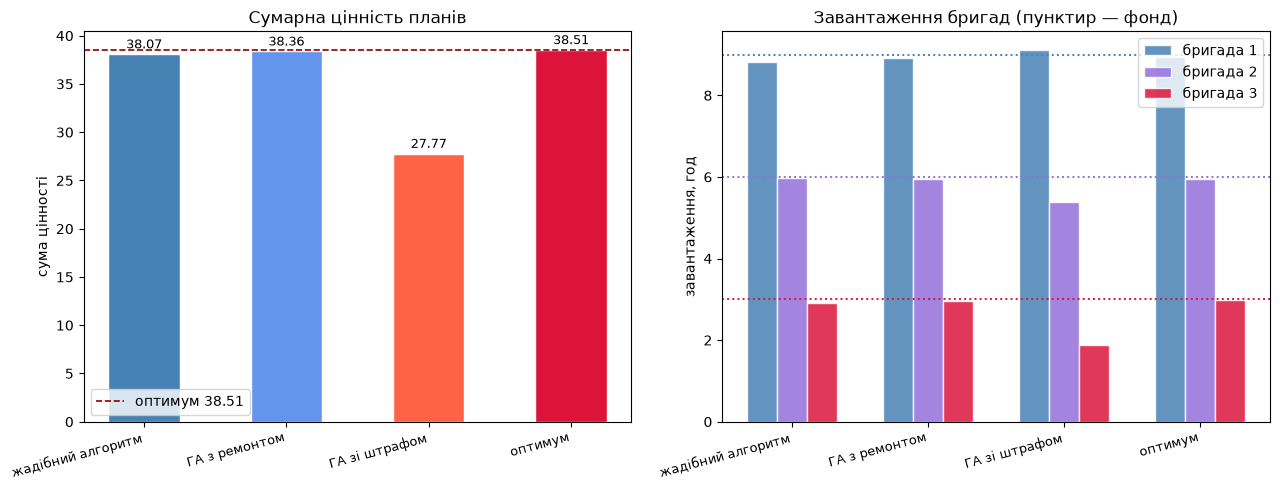

In [21]:
labels  = list(plans.keys())
values_ = [value(p) for p in plans.values()]
loads_  = [load(p) for p in plans.values()]

x     = np.arange(len(labels))
width = 0.22

# синій → червоний градієнт для планів
bar_colors = ["steelblue", "cornflowerblue", "tomato", "crimson"]
brigade_colors = ["steelblue", "mediumpurple", "crimson"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- лівий: сума цінності ---
bars = axes[0].bar(x, values_, color=bar_colors, edgecolor="white", width=0.5)
axes[0].axhline(best, color="darkred", linestyle="--", linewidth=1.2,
                label=f"оптимум {best:.2f}")
for bar, v_ in zip(bars, values_):
    axes[0].text(bar.get_x() + bar.get_width() / 2, v_ + 0.3,
                 f"{v_:.2f}", ha="center", va="bottom", fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=15, ha="right", fontsize=9)
axes[0].set_ylabel("сума цінності")
axes[0].set_title("Сумарна цінність планів")
axes[0].legend()

# --- правий: завантаження бригад ---
brigade_labels = ["бригада 1", "бригада 2", "бригада 3"]
for i, (col, lbl) in enumerate(zip(brigade_colors, brigade_labels)):
    axes[1].bar(x + (i - 1) * width,
                [ld[i] for ld in loads_],
                width=width, color=col, label=lbl, edgecolor="white", alpha=0.85)
for f, col in zip(FUND, brigade_colors):
    axes[1].axhline(f, color=col, linestyle=":", linewidth=1.4)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=15, ha="right", fontsize=9)
axes[1].set_ylabel("завантаження, год")
axes[1].set_title("Завантаження бригад (пунктир — фонд)")
axes[1].legend()

fig.tight_layout()
plt.show()

---

## Звіт

### 1. Що дала нечітка система у тестовій точці і що змінило одне правило?

**До зміни правила**

За вхідних умов — танення снігу 5.516 см/добу та обсяг спуску 54.093 млн м³ — система прогнозує рівень повені **4.021 м** (метод центроїда) або **4.000 м** (середнє максимумів). Обидва методи вказують на середній рівень повені: за таких умов найімовірніше повінь буде помірною і не досягне небезпечних значень.

Невелика різниця між методами пояснюється тим, що центроїд враховує всю форму агрегованої фігури (звідси 4.021 м), тоді як середнє максимумів орієнтується лише на пік — рівно 4.000 м, що відповідає вершині терму «середній».

**Змінене правило**

Найсильніше правило у цій точці — «ЯКЩО танення **середнє** І спуск **середній** ТО повінь **середня**» (сила 0.897). Замінимо його висновок на «→ повінь **висока**».

**Після зміни правила**

Прогноз рівня повені зріс до **6.654 м** (центроїд) і **7.782 м** (середнє максимумів) — тобто з помірного рівня до майже максимального. Одне правило з найбільшою силою визначило весь результат: за тих самих погодних умов система тепер прогнозує небезпечну повінь.

---

### 2. Скільки правил дають кластеризації і чи допомогло налаштування?

Правил у субтрактивної кластеризації: ra = 0.3 → 19 · ra = 0.5 → 8 · ra = 0.8 → 2

| Модель | Навчальна RMSE | Тестова RMSE | Що налаштовано |
|---|---|---|---|
| Прогноз середнім | 1.125 | 0.861 | — |
| 3 правила c-means, до налаштування *(центри та ширини взяті безпосередньо з кластеризації, не оптимізувались)* | 1.056 | 0.638 | — |
| 3 правила c-means, після налаштування | 0.691 | 1.189 | центри, ширини та вихідні константи кожного правила оптимізовано методом L-BFGS-B |

До налаштування модель вже перевершує базову лінію на тестових даних (0.638 < 0.861). Після налаштування навчальна похибка впала до 0.691, але тестова зросла до 1.189 — ознака перенавчання на малій вибірці.

---

### 3. Наскільки кожен спосіб наблизився до оптимуму?

| План | Сума цінності | Завантаження, год (бр.1 / бр.2 / бр.3) | Перевищення, год | % оптимуму |
|---|---|---|---|---|
| жадібний алгоритм | 38.072 | 8.812 / 5.968 / 2.906 | 0 | 98.9% |
| генетичний алгоритм з ремонтом | 38.363 | 8.906 / 5.957 / 2.969 | 0 | 99.6% |
| генетичний алгоритм зі штрафом | 27.768 | 9.110 / 5.376 / 1.872 | 0.1105 | 72.1% |
| оптимум | 38.512 | 8.990 / 5.990 / 2.910 | 0 | 100% |

Найближчим до оптимуму виявився **генетичний алгоритм з ремонтом**: сума цінності 38.363 при максимально можливих 38.512 — тобто 99.6% від точного оптимуму, і жодна бригада не перевищила свій фонд часу.

Генетичний алгоритм зі штрафом показав найгірший результат серед усіх трьох алгоритмів — 72.1% від оптимуму — і єдиний порушив обмеження: штраф 10 × 0.1105 = 1.105 виявився занадто малим, щоб утримати першу бригаду у допустимій зоні.
